# 08 Site-based validation

**Manuscript outputs:** Figures 9 and 10; Tables S3, S4 and S5; statistics for Sections 3.4 and 4.2.6

**Inputs:** 82 Survey123 sites, completed GLORYS transect shapefile (stage 06)

Inputs are read from `Master_raw/`; everything produced is written to `Outputs/` (manuscript figures in `Outputs/Figures`, tables in `Outputs/Tables`). The first code cell lists every path. Run the cells in order.

# Site-based validation of shoreline change rates, Kenyan coast

Survey123 field survey (16–19 July 2025, 82 sites) compared with DSAS WLR shoreline change rates (2000–2024).

The notebook runs in numbered steps. Each step writes its outputs to `OUT_DIR` (tables in `tables/`, figures in `figures/`) and prints the numbers used in the manuscript and the response to reviewers (Reviewer 1, comment 6).

| Step | What it produces | Manuscript |
|---|---|---|
| 1 | Cleaned site table | Section 3.4 |
| 2 | Survey summary, classification by zone, **Figure 9** | Sections 3.4, 4.2.6 |
| 3 | Beach width by category, Kruskal–Wallis, **Figure 10** | Section 4.2.6 |
| 4 | Human interventions, chi-square and Fisher tests | Section 4.2.6 |
| 5 | DSAS transects classed from the WLR 90% CI | Table 2 rule |
| 6 | Raw site-to-transect table and raw confusion counts | Section 4.2.6 |
| 7 | Confusion matrix, agreement, Cohen's kappa, per-class recall, by zone, figure | Section 4.2.6 |
| 8 | Bootstrap 95% CIs for kappa, resampling localities | Section 4.2.6 |
| 9 | Trend test of WLR across field classes (Jonckheere–Terpstra) | Section 4.2.6 |
| 10 | Sensitivity: matching distance, neighbourhood class, seawall sites excluded | Section 4.2.6 |
| 11 | Report and text for the manuscript placeholders | |

**Class rules.** DSAS transect: *eroding* if WLR + WCI < 0, *accreting* if WLR − WCI > 0, otherwise *stable* (WCI is the 90% confidence interval). Field: Erosion Hotspot Area → eroding, Stable Area → stable, Accretion Hotspot Area → accreting; "other" and blank sites are reported but not used in the matrix.

## 0. Settings
Inputs are read from `DATA_DIR`; everything is written to `OUT_DIR`.

In [ ]:
from pathlib import Path

# ------------------------------------------------------------
# REPOSITORY ROOT: first folder above this notebook that contains Master_raw
# (e.g. D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024)
# ------------------------------------------------------------
_here = Path.cwd().resolve()
ROOT = next((p for p in (_here, *_here.parents) if (p / "Master_raw").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError(f"No Master_raw folder found above {_here}. Open this notebook inside the repository.")
RAW = ROOT / "Master_raw"          # inputs
OUTPUTS = ROOT / "Outputs"         # everything this repository produces
FIGURES = OUTPUTS / "Figures"      # manuscript figures
TABLES = OUTPUTS / "Tables"        # manuscript tables
TEXT_STATS = TABLES / "Text_statistics"
for _d in (FIGURES, TABLES, TEXT_STATS):
    _d.mkdir(parents=True, exist_ok=True)
OVERWRITE = True                   # re-running replaces this notebook's earlier outputs


def first_existing(*candidates):
    """Return the first path that exists (otherwise the first one)."""
    for c in candidates:
        if Path(c).exists():
            return Path(c)
    return Path(candidates[0])


def save_table(df, name, index=False, folder=None):
    path = (folder or TABLES) / f"{name}.csv"
    df.to_csv(path, index=index, encoding="utf-8-sig")
    print("Saved:", path.relative_to(ROOT))


def save_figure(fig, name, dpi=600):
    for ext in ("png", "pdf"):
        fig.savefig(FIGURES / f"{name}.{ext}", dpi=dpi, bbox_inches="tight")
    print("Saved:", (FIGURES / f"{name}.png").relative_to(ROOT))


def remove_existing(*files):
    for f in map(Path, files):
        for t in (list(f.parent.glob(f.stem + ".*")) if f.suffix == ".shp" else [f]):
            if t.exists():
                if not OVERWRITE:
                    raise FileExistsError(t)
                t.unlink()

# ------------------------------------------------------------
# INPUTS AND OUTPUT FOLDERS FOR THIS NOTEBOOK
# ------------------------------------------------------------
TRANSECT_RATES_DIR = RAW / "Transect_rates"
GLORYS_DIR = OUTPUTS / "GLORYS_attribution"
COMPLETE_SHP = first_existing(GLORYS_DIR / "GLORYS_Transects_Shapefile" / "ke_transects_GLORYS_complete_zoned.shp",
                              TRANSECT_RATES_DIR / "ke_transects_GLORYS_complete_zoned.shp")
SITE_VALIDATION_DIR = OUTPUTS / "Site_validation"
SITES_SHP = RAW / "Ground_surveys" / "coastal_erosion_82sites.shp"

print("Repository root:", ROOT)
for _label, _p in [("SITES_SHP", SITES_SHP), ("COMPLETE_SHP", COMPLETE_SHP)]:
    print(f"  {'ok     ' if _p.exists() else 'MISSING'} {_label}: {_p.relative_to(ROOT)}")

import os


OUT_DIR  = str(SITE_VALIDATION_DIR)

SITES_SHP     = str(SITES_SHP)               # 82 Survey123 points with all attributes
TRANSECTS_SHP = str(COMPLETE_SHP)    # DSAS transects with rate fields

WLR_COL = "WLR"   # DSAS weighted linear regression rate (m/yr)
CI_COL  = "WCI"   # DSAS confidence interval of WLR (set to 90% in DSAS)

UTM       = "EPSG:32737"   # WGS 84 / UTM zone 37S
MAX_DIST  = 150            # m, maximum site-to-transect distance for a match
WINDOW    = 100            # m, radius for the neighbourhood (modal class) check
CLUSTER_M = 1000           # m, sites closer than this are one locality for the bootstrap
N_BOOT    = 2000           # bootstrap replicates
N_PERM    = 9999           # permutations for the trend test
SEED      = 42

TAB_DIR = os.path.join(OUT_DIR, "tables")
FIG_DIR = os.path.join(OUT_DIR, "figures")
for d in (OUT_DIR, TAB_DIR, FIG_DIR):
    os.makedirs(d, exist_ok=True)
print("Sites:    ", SITES_SHP, os.path.exists(SITES_SHP))
print("Transects:", TRANSECTS_SHP, os.path.exists(TRANSECTS_SHP))
print("Output:   ", OUT_DIR)

Repository root: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024
  ok      SITES_SHP: Master_raw\Ground_surveys\coastal_erosion_82sites.shp
  ok      COMPLETE_SHP: Outputs\GLORYS_attribution\GLORYS_Transects_Shapefile\ke_transects_GLORYS_complete_zoned.shp
Sites:     D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Master_raw\Ground_surveys\coastal_erosion_82sites.shp True
Transects: D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\GLORYS_attribution\GLORYS_Transects_Shapefile\ke_transects_GLORYS_complete_zoned.shp True
Output:    D:\1_GIt_Repositories\kenya-shoreline-change-2000-2024\Outputs\Site_validation


## Setup
If a package is missing: `pip install pandas geopandas shapely numpy scipy scikit-learn matplotlib`

In [ ]:
import re
os.environ.setdefault("SHAPE_RESTORE_SHX", "YES")   # rebuilds a missing .shx index

import geopandas as gpd
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from scipy import stats
from scipy.cluster.hierarchy import fcluster, linkage
from sklearn.metrics import cohen_kappa_score, confusion_matrix

%matplotlib inline
pd.set_option("display.width", 160)
rng = np.random.default_rng(SEED)

CLASSES = ["eroding", "stable", "accreting"]          # ordinal order
FIELD_MAP = {"Erosion Hotspot Area": "eroding", "Stable Area": "stable", "Accretion Hotspot Area": "accreting"}
LABELS = {"Erosion Hotspot Area": "Erosion hotspot", "Stable Area": "Stable",
          "Accretion Hotspot Area": "Accretion hotspot", "other": "Other", "Unclassified": "Unclassified"}
COLOURS = {"Erosion hotspot": "#eb6834", "Accretion hotspot": "#2a78d6", "Stable": "#8c8b87",
           "Other": "#c9c8c3", "Unclassified": "#e4e3de"}
plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.edgecolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})

REPORT = []
def say(*lines):
    for l in lines:
        print(l); REPORT.append(str(l))

def save_fig(fig, name):
    for ext in ("png", "pdf"):
        fig.savefig(os.path.join(FIG_DIR, f"{name}.{ext}"), dpi=300, bbox_inches="tight")

## Step 1. Load and clean the site data
Beach width is free text ('24 m', '100 meter'), so the first number is taken. The free-text intervention field is grouped into types.

In [ ]:
def parse_width(v):
    if pd.isna(v):
        return np.nan
    m = re.search(r"\d+(?:\.\d+)?", str(v))
    return float(m.group()) if m else np.nan

def intervention_type(v):
    t = str(v).strip().lower() if pd.notna(v) else ""
    if t in ("", "na", "none", "no", "nan"):
        return "None recorded"
    if "nearby" in t:
        return "None at site (seawall on adjacent plot)"
    if "broken" in t:
        return "Seawall (damaged)"
    if "boulder" in t:
        return "Boulders / revetment"
    if "vegetation" in t:
        return "Planted vegetation"
    if "sea wall" in t or "seawall" in t or t == "yes":
        return "Seawall"
    return "Other"

sites = gpd.read_file(SITES_SHP)
if sites.crs is None:
    sites = sites.set_crs("EPSG:4326")
if sites.geometry.is_empty.any() or sites.geometry.isna().any():   # fall back to lat/lon fields
    lat = next(c for c in sites.columns if c.lower() in ("lat", "latitude", "y"))
    lon = next(c for c in sites.columns if c.lower() in ("lon", "long", "longitude", "x"))
    sites = gpd.GeoDataFrame(sites.drop(columns="geometry"),
                             geometry=gpd.points_from_xy(sites[lon], sites[lat]), crs="EPSG:4326")

sites["zone"] = sites["field_7"].str.strip()
sites["category_raw"] = sites["how_would_"].fillna("Unclassified").replace("", "Unclassified").str.strip()
sites["category"] = sites["category_raw"].map(LABELS).fillna("Other")
sites["field_class"] = sites["category_raw"].map(FIELD_MAP)
sites["beach_width_m"] = sites["beach_widt"].map(parse_width)
sites["intervention"] = sites["evidence_o"].map(intervention_type)
sites["has_intervention"] = ~sites["intervention"].str.startswith("None")
sites["seawall"] = sites["intervention"].isin(["Seawall", "Seawall (damaged)", "Boulders / revetment"])
sites["date"] = pd.to_datetime(sites["date_of_su"])
sites["tide"] = sites["tide_condi"].str.strip()
wgs = sites.to_crs("EPSG:4326")
sites["lon"], sites["lat"] = wgs.geometry.x.round(6), wgs.geometry.y.round(6)
sites = sites.to_crs(UTM)

# localities for the bootstrap: sites within CLUSTER_M of each other (single linkage)
xy = np.c_[sites.geometry.x, sites.geometry.y]
sites["locality"] = fcluster(linkage(xy, "single"), t=CLUSTER_M, criterion="distance")

sites.drop(columns="geometry").to_csv(os.path.join(TAB_DIR, "step1_sites_cleaned.csv"), index=False)
print(f"{len(sites)} sites loaded; {sites.locality.nunique()} localities at {CLUSTER_M} m")
sites[["station_na", "site_name", "zone", "date", "tide", "category", "beach_width_m", "intervention", "locality", "lat", "lon"]].head(10)

82 sites loaded; 16 localities at 1000 m


,station_na,site_name,zone,date,tide,category,beach_width_m,intervention,locality,lat,lon
0,003,003,Kilifi,2025-07-16,Low,Erosion hotspot,24.0,None recorded,1,-2.994164,40.198472
1,004,004,Kilifi,2025-07-16,Low,Erosion hotspot,NaN,None recorded,1,-2.993447,40.200349
2,005,Navy 005,Kilifi,2025-07-16,Low,Erosion hotspot,128.0,None recorded,1,-2.993553,40.200548
3,006,Navy2,Kilifi,2025-07-16,Low,Erosion hotspot,NaN,None recorded,1,-2.993157,40.201787
4,MW-01,Mwandamo,Kwale-Mombasa,2025-07-16,Low,Erosion hotspot,190.0,None recorded,7,-4.456846,39.497580
5,MW-02,Mwandamo,Kwale-Mombasa,2025-07-16,Low,Erosion hotspot,168.0,None recorded,7,-4.457222,39.498296
6,MW-03,Mwandamo,Kwale-Mombasa,2025-07-16,Low,Erosion hotspot,300.0,None recorded,7,-4.457433,39.498796
7,MW-04,Mwandamo,Kwale-Mombasa,2025-07-16,Low,Erosion hotspot,110.0,Seawall,7,-4.455370,39.499289
8,GZ-01,Gazi,Kwale-Mombasa,2025-07-16,Low,Erosion hotspot,45.0,Seawall,6,-4.428979,39.511974
9,GZ-02,Gazi,Kwale-Mombasa,2025-07-16,Low,Erosion hotspot,41.0,Seawall,6,-4.429203,39.511959


## Step 2. Survey summary, classification by zone and Figure 9

STEP 2  SURVEY SUMMARY
Sites surveyed: 82
Survey dates: 16 July 2025 to 19 July 2025 (4 days)
Sites per zone: Kilifi = 44, Kwale-Mombasa = 38
Tide stage: Low = 69, High = 13
Other / unclassified sites (4): 011 (other), 025 (unclassified), 032 (other), 042 (unclassified)

category_fig9  Erosion hotspot  Stable  Accretion hotspot  Other / unclassified
zone                                                                           
Kilifi                      18      13                  9                     4
Kwale-Mombasa               18      14                  6                     0
Total                       36      27                 15                     4
Saved: Outputs\Figures\Figure_9_Site_categories_by_zone.png


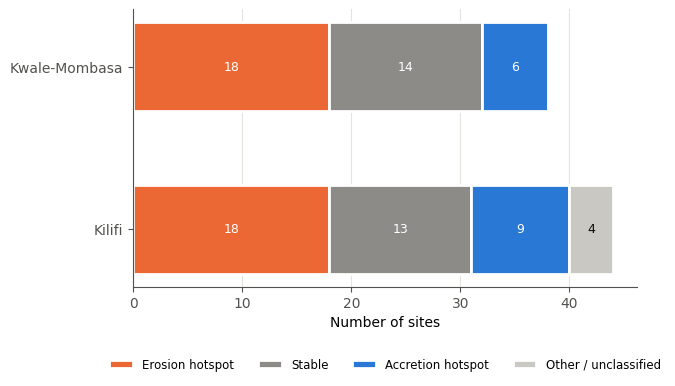

In [ ]:
# Combine "Other" and "Unclassified" into one category for the summary, table and Figure 9
MERGED = "Other / unclassified"
sites["category_fig9"] = sites["category"].replace({"Other": MERGED, "Unclassified": MERGED})
COLOURS[MERGED] = "#c9c8c3"

merged_sites = sites.loc[sites.category_fig9 == MERGED]
say("STEP 2  SURVEY SUMMARY",
    f"Sites surveyed: {len(sites)}",
    f"Survey dates: {sites.date.min():%d %B %Y} to {sites.date.max():%d %B %Y} ({sites.date.dt.date.nunique()} days)",
    "Sites per zone: " + ", ".join(f"{k} = {v}" for k, v in sites.zone.value_counts().items()),
    "Tide stage: " + ", ".join(f"{k} = {v}" for k, v in sites.tide.value_counts().items()),
    f"{MERGED} sites ({len(merged_sites)}): "
    + ", ".join(f"{s} ({c.lower()})" for s, c in zip(merged_sites.station_na.astype(str), merged_sites.category)))

order = ["Erosion hotspot", "Stable", "Accretion hotspot", MERGED]
tab = pd.crosstab(sites.zone, sites.category_fig9).reindex(columns=order, fill_value=0)
tab.loc["Total"] = tab.sum()
tab.to_csv(os.path.join(TAB_DIR, "step2_classification_by_zone.csv"))
say("", tab.to_string())

fig, ax = plt.subplots(figsize=(6.5, 3.6))
zones = [z for z in tab.index if z != "Total"]
left = np.zeros(len(zones))
for cat in order:
    v = tab.loc[zones, cat].values
    if v.sum() == 0:
        continue
    ax.barh(zones, v, left=left, color=COLOURS[cat], edgecolor="white", linewidth=2, height=0.55, label=cat)
    for i, n in enumerate(v):
        if n >= 3:
            ax.text(left[i] + n / 2, i, str(n), ha="center", va="center", fontsize=9,
                    color="white" if cat in ("Erosion hotspot", "Accretion hotspot", "Stable") else "#0b0b0b")
    left += v
ax.set_xlabel("Number of sites")
ax.grid(axis="x", color="#e4e3de"); ax.set_axisbelow(True)
ax.legend(ncol=4, frameon=False, fontsize=8.5, loc="upper center", bbox_to_anchor=(0.5, -0.22))
save_fig(fig, "fig9_site_categories_by_zone"); save_figure(fig, "Figure_9_Site_categories_by_zone", dpi=300); plt.show()

## Step 3. Beach width by category and Figure 10
Kruskal–Wallis across erosion, stable and accretion sites, for all sites and by tide stage.


STEP 3  BEACH WIDTH
Recorded at 77 of 82 sites; range 0.0 to 300.0 m; median 39.3 m
                   count   min   25%   50%    75%    max
category                                                
Accretion hotspot   14.0  10.0  23.6  36.6  115.5  144.0
Erosion hotspot     33.0   0.0  32.0  39.8   61.0  300.0
Other                2.0  16.0  28.5  41.0   53.5   66.0
Stable              26.0  15.0  21.2  41.3   53.0  105.0
Unclassified         2.0  23.0  28.5  34.0   39.5   45.0
Kruskal-Wallis (erosion / stable / accretion): H = 1.37, p = 0.504, n = 73
  High tide only: H = 3.20, p = 0.202, n = 13
  Low tide only: H = 0.03, p = 0.986, n = 60
Saved: Outputs\Figures\Figure_10_Beach_width_by_category.png


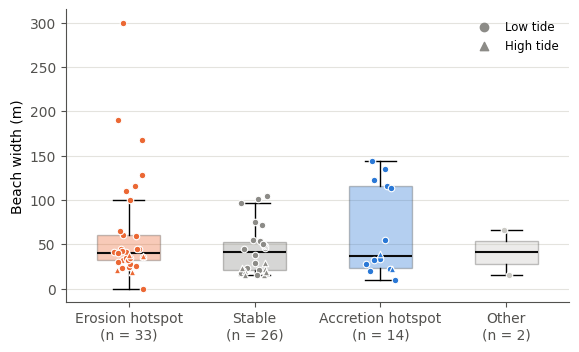

In [ ]:
bw = sites.dropna(subset=["beach_width_m"])
summ = bw.groupby("category").beach_width_m.describe()[["count", "min", "25%", "50%", "75%", "max"]].round(1)
summ.to_csv(os.path.join(TAB_DIR, "step3_beach_width_by_category.csv"))
main = bw[bw.field_class.notna()]
h, p = stats.kruskal(*[g.beach_width_m for _, g in main.groupby("field_class")])
say("", "STEP 3  BEACH WIDTH",
    f"Recorded at {len(bw)} of {len(sites)} sites; range {bw.beach_width_m.min():.1f} to {bw.beach_width_m.max():.1f} m; "
    f"median {bw.beach_width_m.median():.1f} m",
    summ.to_string(),
    f"Kruskal-Wallis (erosion / stable / accretion): H = {h:.2f}, p = {p:.3f}, n = {len(main)}")
for tide, sub in main.groupby("tide"):
    g = [x.beach_width_m for _, x in sub.groupby("field_class") if len(x) > 1]
    if len(g) >= 2:
        h2, p2 = stats.kruskal(*g)
        say(f"  {tide} tide only: H = {h2:.2f}, p = {p2:.3f}, n = {len(sub)}")

cats = [c for c in ["Erosion hotspot", "Stable", "Accretion hotspot", "Other"] if c in bw.category.values]
data = [bw.loc[bw.category == c, "beach_width_m"].values for c in cats]
fig, ax = plt.subplots(figsize=(6.5, 3.8))
bp = ax.boxplot(data, widths=0.5, patch_artist=True, showfliers=False, medianprops=dict(color="#0b0b0b", linewidth=1.5))
for patch, c in zip(bp["boxes"], cats):
    patch.set_facecolor(COLOURS[c]); patch.set_alpha(0.35); patch.set_edgecolor("#52514e")
jit = np.random.default_rng(1)
for i, c in enumerate(cats, start=1):
    sub = bw[bw.category == c]
    for tide, m in (("Low", "o"), ("High", "^")):
        s2 = sub[sub.tide == tide]
        ax.scatter(i + jit.uniform(-0.12, 0.12, len(s2)), s2.beach_width_m, s=22, marker=m,
                   color=COLOURS[c], edgecolor="white", linewidth=0.8, zorder=3)
ax.set_xticks(range(1, len(cats) + 1))
ax.set_xticklabels([f"{c}\n(n = {len(d)})" for c, d in zip(cats, data)])
ax.set_ylabel("Beach width (m)")
ax.scatter([], [], marker="o", color="#8c8b87", label="Low tide"); ax.scatter([], [], marker="^", color="#8c8b87", label="High tide")
ax.legend(frameon=False, fontsize=8.5, loc="upper right")
ax.grid(axis="y", color="#e4e3de"); ax.set_axisbelow(True)
save_fig(fig, "fig10_beach_width_by_category"); save_figure(fig, "Figure_10_Beach_width_by_category", dpi=300); plt.show()

## Step 4. Human interventions

In [ ]:
it = sites.intervention.value_counts()
it.to_csv(os.path.join(TAB_DIR, "step4_interventions.csv"))
cls = sites[sites.field_class.notna()]
ct = pd.crosstab(cls.has_intervention, cls.field_class).reindex(columns=CLASSES, fill_value=0)
ct.to_csv(os.path.join(TAB_DIR, "step4_intervention_by_class.csv"))
chi2, pc, dof, exp = stats.chi2_contingency(ct)
orr, pf = stats.fisher_exact(pd.crosstab(cls.has_intervention, cls.field_class.eq("eroding")).values)
say("", "STEP 4  HUMAN INTERVENTIONS",
    f"Sites with an intervention: {sites.has_intervention.sum()} of {len(sites)}", it.to_string(),
    "Intervention (rows) by field class (columns):", ct.to_string(),
    f"Chi-square: chi2 = {chi2:.2f}, df = {dof}, p = {pc:.3f}" + ("  (expected counts < 5)" if (exp < 5).any() else ""),
    f"Fisher exact, intervention vs erosion hotspot: odds ratio = {orr:.2f}, p = {pf:.3f}")


STEP 4  HUMAN INTERVENTIONS
Sites with an intervention: 38 of 82
intervention
None recorded                              43
Seawall                                    34
Boulders / revetment                        2
Seawall (damaged)                           1
Planted vegetation                          1
None at site (seawall on adjacent plot)     1
Intervention (rows) by field class (columns):
field_class       eroding  stable  accreting
has_intervention                            
False                  18      13         11
True                   18      14          4
Chi-square: chi2 = 2.86, df = 2, p = 0.239
Fisher exact, intervention vs erosion hotspot: odds ratio = 1.33, p = 0.649


## Step 5. Load the DSAS transects and class them
Transects without a usable rate (empty, or DSAS placeholder values such as −9999) are dropped.

In [ ]:
tr = gpd.read_file(TRANSECTS_SHP).to_crs(UTM)
for c in (WLR_COL, CI_COL):
    tr[c] = pd.to_numeric(tr[c], errors="coerce")
ok = tr[WLR_COL].between(-1000, 1000) & tr[CI_COL].between(0, 1000)
n_all = len(tr); tr = tr[ok].copy()

def dsas_class(wlr, ci):
    if wlr + ci < 0:
        return "eroding"
    if wlr - ci > 0:
        return "accreting"
    return "stable"

tr["dsas_class"] = [dsas_class(w, c) for w, c in zip(tr[WLR_COL], tr[CI_COL])]
tr["transect_id"] = tr["BaselineID"].astype(str) + "_" + tr["TransOrder"].astype(str)
say("", "STEP 5  DSAS TRANSECTS",
    f"Transects: {n_all}; rate-bearing: {len(tr)}; dropped: {n_all - len(tr)}",
    "Classes: " + ", ".join(f"{k} = {v} ({v / len(tr):.1%})" for k, v in tr.dsas_class.value_counts().reindex(CLASSES).items()))


STEP 5  DSAS TRANSECTS
Transects: 12455; rate-bearing: 12452; dropped: 3
Classes: eroding = 2022 (16.2%), stable = 7772 (62.4%), accreting = 2658 (21.3%)


## Step 6. Match each site to its nearest transect: raw table and raw confusion counts
Also records the modal class of all transects within `WINDOW` m of each site (used in step 10).

In [ ]:
cols = [c for c in ["transect_id", "BaselineID", "TransOrder", "ShrCount", WLR_COL, "WR2", CI_COL, "WSE",
                    "LRR", "LCI90", "EPR", "EPRUNC", "NSM", "SCE", "dsas_class"] if c in tr.columns]
m = gpd.sjoin_nearest(sites, tr[cols + ["geometry"]], how="left", distance_col="dist_m")
m = m.sort_values("dist_m").drop_duplicates("globalid").drop(columns="index_right", errors="ignore")

buf = sites[["globalid", "geometry"]].copy(); buf["geometry"] = buf.buffer(WINDOW)
hood = gpd.sjoin(buf, tr[["dsas_class", "geometry"]], how="left", predicate="intersects")
m = m.merge(hood.dropna(subset=["dsas_class"]).groupby("globalid").dsas_class
            .agg(lambda x: x.value_counts().idxmax()).rename("dsas_class_hood"), on="globalid", how="left")
m = m.merge(hood.groupby("globalid").dsas_class.count().rename("n_transects_hood"), on="globalid", how="left")

m["matched"] = m.dist_m <= MAX_DIST
m["in_matrix"] = m.matched & m.field_class.notna()
raw_cols = ["globalid", "station_na", "site_name", "zone", "locality", "date_of_su", "tide", "lat", "lon",
            "category_raw", "field_class", "intervention", "seawall", "dist_m", "matched", "in_matrix"] + cols + \
           ["dsas_class_hood", "n_transects_hood"]
raw = pd.DataFrame(m[raw_cols]).sort_values(["zone", "lat"])
raw.to_csv(os.path.join(TAB_DIR, "step6_site_transect_raw.csv"), index=False)

M = raw[raw.in_matrix].copy()
counts = pd.crosstab(M.field_class, M.dsas_class, rownames=["Field"], colnames=["DSAS"], margins=True, margins_name="Total")
counts = counts.reindex(index=CLASSES + ["Total"], columns=CLASSES + ["Total"], fill_value=0)
counts.to_csv(os.path.join(TAB_DIR, "step6_confusion_counts.csv"))
say("", "STEP 6  SITE-TO-TRANSECT MATCHING",
    f"Distance to nearest transect: median {raw.dist_m.median():.0f} m, max {raw.dist_m.max():.0f} m",
    f"Sites in the matrix: {len(M)} (excluded: {raw.field_class.isna().sum()} other/unclassified, "
    f"{(raw.field_class.notna() & ~raw.matched).sum()} farther than {MAX_DIST} m)",
    "Raw confusion counts (rows = field, columns = DSAS):", counts.to_string())
raw.sort_values("dist_m", ascending=False)[["station_na", "site_name", "zone", "dist_m", "field_class", "dsas_class"]].head(8)


STEP 6  SITE-TO-TRANSECT MATCHING
Distance to nearest transect: median 15 m, max 255 m
Sites in the matrix: 76 (excluded: 4 other/unclassified, 2 farther than 150 m)
Raw confusion counts (rows = field, columns = DSAS):
DSAS       eroding  stable  accreting  Total
Field                                       
eroding          3      33          0     36
stable           4      16          7     27
accreting        1       3          9     13
Total            8      52         16     76


,station_na,site_name,zone,dist_m,field_class,dsas_class
81,GZ -07,Gazi,Kwale-Mombasa,254.772450,accreting,stable
80,GZ - 06,Gazi,Kwale-Mombasa,236.040231,accreting,stable
79,GZ-05,Gazi,Kwale-Mombasa,137.550638,accreting,stable
78,012,Shella,Kilifi,117.986458,accreting,accreting
77,GZ-02,Gazi,Kwale-Mombasa,108.469918,eroding,stable
76,GZ-01,Gazi,Kwale-Mombasa,98.338245,eroding,stable
75,KR-04,Kongo river,Kwale-Mombasa,89.881535,stable,eroding
74,MW-02,Mwandamo,Kwale-Mombasa,74.824280,eroding,stable


## Step 7. Confusion matrix, agreement and Cohen's kappa
Linear-weighted kappa uses the order eroding < stable < accreting, so eroding vs accreting counts as a larger disagreement than eroding vs stable.


STEP 7  AGREEMENT (nearest transect)
n = 76; overall agreement = 36.8%; Cohen's kappa = 0.06; linear-weighted kappa = 0.18
           n_field  n_dsas  recall  precision
cls                                          
eroding         36       8   0.083      0.375
stable          27      52   0.593      0.308
accreting       13      16   0.692      0.562
                n  agreement  kappa  weighted_kappa
zone                                               
Kilifi         40      0.475  0.254           0.398
Kwale-Mombasa  36      0.250 -0.234          -0.189
Direction agreement where both show change: 92% (n = 13)


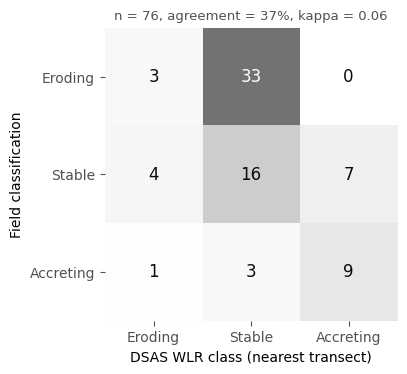

In [ ]:
def agreement(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred, labels=CLASSES)
    n = cm.sum()
    return dict(cm=cm, n=int(n), oa=np.trace(cm) / n,
                kappa=cohen_kappa_score(y_true, y_pred, labels=CLASSES),
                wkappa=cohen_kappa_score(y_true, y_pred, labels=CLASSES, weights="linear"))

A = agreement(M.field_class, M.dsas_class)
rows = []
for i, c in enumerate(CLASSES):
    rows.append(dict(cls=c, n_field=A["cm"][i].sum(), n_dsas=A["cm"][:, i].sum(),
                     recall=A["cm"][i, i] / A["cm"][i].sum() if A["cm"][i].sum() else np.nan,
                     precision=A["cm"][i, i] / A["cm"][:, i].sum() if A["cm"][:, i].sum() else np.nan))
perclass = pd.DataFrame(rows).set_index("cls").round(3)
perclass.to_csv(os.path.join(TAB_DIR, "step7_per_class_recall_precision.csv"))

zrows = []
for z, zz in M.groupby("zone"):
    a = agreement(zz.field_class, zz.dsas_class)
    zrows.append(dict(zone=z, n=a["n"], agreement=round(a["oa"], 3), kappa=round(a["kappa"], 3), weighted_kappa=round(a["wkappa"], 3)))
byzone = pd.DataFrame(zrows).set_index("zone")
byzone.to_csv(os.path.join(TAB_DIR, "step7_agreement_by_zone.csv"))

d = M[(M.field_class != "stable") & (M.dsas_class != "stable")]
say("", "STEP 7  AGREEMENT (nearest transect)",
    f"n = {A['n']}; overall agreement = {A['oa']:.1%}; Cohen's kappa = {A['kappa']:.2f}; linear-weighted kappa = {A['wkappa']:.2f}",
    perclass.to_string(), byzone.to_string(),
    f"Direction agreement where both show change: {(d.field_class == d.dsas_class).mean():.0%} (n = {len(d)})")

fig, ax = plt.subplots(figsize=(4.4, 3.8))
cm = A["cm"]
ax.imshow(cm, cmap="Greys", vmin=0, vmax=max(cm.max(), 1) * 1.6)
for i in range(3):
    for j in range(3):
        ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=12, color="white" if cm[i, j] > cm.max() * 0.6 else "#0b0b0b")
ax.set_xticks(range(3)); ax.set_yticks(range(3))
ax.set_xticklabels([c.capitalize() for c in CLASSES]); ax.set_yticklabels([c.capitalize() for c in CLASSES])
ax.set_xlabel("DSAS WLR class (nearest transect)"); ax.set_ylabel("Field classification")
ax.set_title(f"n = {A['n']}, agreement = {A['oa']:.0%}, kappa = {A['kappa']:.2f}", fontsize=9.5, color="#52514e")
for s in ax.spines.values():
    s.set_visible(False)
save_fig(fig, "fig_confusion_matrix"); plt.show()

## Step 8. Bootstrap 95% confidence intervals, resampling localities
Sites close together are not independent, so whole localities (sites within `CLUSTER_M` m) are resampled rather than individual sites.

In [ ]:
locs = M.locality.unique()
boot = []
for _ in range(N_BOOT):
    pick = rng.choice(locs, size=len(locs), replace=True)
    s = pd.concat([M[M.locality == l] for l in pick])
    if s.field_class.nunique() < 2 or s.dsas_class.nunique() < 2:
        continue
    boot.append((np.mean(s.field_class == s.dsas_class),
                 cohen_kappa_score(s.field_class, s.dsas_class, labels=CLASSES),
                 cohen_kappa_score(s.field_class, s.dsas_class, labels=CLASSES, weights="linear")))
boot = np.array(boot)
ci = np.nanpercentile(boot, [2.5, 97.5], axis=0)
bt = pd.DataFrame({"estimate": [A["oa"], A["kappa"], A["wkappa"]], "ci_low": ci[0], "ci_high": ci[1]},
                  index=["overall_agreement", "kappa", "weighted_kappa"]).round(3)
bt.to_csv(os.path.join(TAB_DIR, "step8_bootstrap_ci.csv"))
say("", f"STEP 8  CLUSTER BOOTSTRAP ({len(locs)} localities, {len(boot)} valid replicates)", bt.to_string())


STEP 8  CLUSTER BOOTSTRAP (16 localities, 2000 valid replicates)
                   estimate  ci_low  ci_high
overall_agreement     0.368   0.183    0.544
kappa                 0.059  -0.233    0.294
weighted_kappa        0.183  -0.176    0.425


## Step 9. Does WLR increase from erosion hotspots to stable to accretion hotspots?
This uses the WLR value itself, so it does not depend on the confidence-interval rule. Jonckheere–Terpstra test with a permutation p-value (one-sided, increasing), plus Spearman's rank correlation.

In [ ]:
def jt_stat(x, g):
    s = 0.0
    for i in range(len(CLASSES)):
        for j in range(i + 1, len(CLASSES)):
            a, b = x[g == i], x[g == j]
            if len(a) and len(b):
                diff = b[None, :] - a[:, None]
                s += (diff > 0).sum() + 0.5 * (diff == 0).sum()
    return s

W = M.dropna(subset=[WLR_COL])
x = W[WLR_COL].to_numpy(float)
g = W.field_class.map({c: i for i, c in enumerate(CLASSES)}).to_numpy()
jt = jt_stat(x, g)
perm = np.array([jt_stat(x, rng.permutation(g)) for _ in range(N_PERM)])
p_jt = (np.sum(perm >= jt) + 1) / (N_PERM + 1)
rho, p_rho = stats.spearmanr(g, x)
med = W.groupby("field_class")[WLR_COL].agg(["count", "median", "mean"]).reindex(CLASSES).round(3)
med.to_csv(os.path.join(TAB_DIR, "step9_wlr_by_field_class.csv"))
say("", "STEP 9  TREND OF WLR ACROSS FIELD CLASSES", med.to_string(),
    f"Jonckheere-Terpstra JT = {jt:.0f}, permutation p = {p_jt:.4f} (one-sided, increasing; {N_PERM} permutations)",
    f"Spearman rho = {rho:.2f}, p = {p_rho:.4f}")


STEP 9  TREND OF WLR ACROSS FIELD CLASSES
             count  median   mean
field_class                      
eroding         36  -0.057  0.096
stable          27   0.200  0.264
accreting       13   3.171  2.580
Jonckheere-Terpstra JT = 1243, permutation p = 0.0002 (one-sided, increasing; 9999 permutations)
Spearman rho = 0.36, p = 0.0012


## Step 10. Sensitivity
(a) matching distance, (b) modal class of transects within `WINDOW` m, (c) sites fronted by seawalls or revetments excluded.

In [ ]:
rows = []
def add(label, sub, col="dsas_class"):
    sub = sub.dropna(subset=[col])
    if len(sub) >= 5 and sub[col].nunique() > 1:
        a = agreement(sub.field_class, sub[col])
        rows.append(dict(test=label, n=a["n"], agreement=round(a["oa"], 3), kappa=round(a["kappa"], 3), weighted_kappa=round(a["wkappa"], 3)))

C_ = raw[raw.field_class.notna()]
add(f"Nearest transect <= {MAX_DIST} m (main)", M)
for dmax in (30, 60, 100, 250):
    add(f"Nearest transect <= {dmax} m", C_[C_.dist_m <= dmax])
add(f"Modal class within {WINDOW} m", M, "dsas_class_hood")
add("Seawall / revetment sites excluded", M[~M.seawall])
add("Seawall / revetment sites only", M[M.seawall])
add("Low-tide observations only", M[M.tide == "Low"])
sens = pd.DataFrame(rows).set_index("test")
sens.to_csv(os.path.join(TAB_DIR, "step10_sensitivity.csv"))
say("", "STEP 10  SENSITIVITY", sens.to_string())


STEP 10  SENSITIVITY
                                     n  agreement  kappa  weighted_kappa
test                                                                    
Nearest transect <= 150 m (main)    76      0.368  0.059           0.183
Nearest transect <= 30 m            54      0.370 -0.018           0.098
Nearest transect <= 60 m            68      0.397  0.092           0.206
Nearest transect <= 100 m           73      0.370  0.050           0.173
Nearest transect <= 250 m           77      0.364  0.053           0.176
Modal class within 100 m            73      0.356  0.040           0.175
Seawall / revetment sites excluded  43      0.395  0.129           0.259
Seawall / revetment sites only      33      0.333 -0.090           0.019
Low-tide observations only          63      0.365  0.091           0.241


In [ ]:
seawall_row = sens.loc["Seawall / revetment sites excluded"] if "Seawall / revetment sites excluded" in sens.index else None
text = (f"Of the {len(raw[raw.field_class.notna()])} classified sites, {A['n']} lay within {MAX_DIST} m of a rate-bearing transect "
        f"(median distance {raw.dist_m.median():.0f} m). Field and DSAS classes agreed at {A['oa']:.0%} of sites "
        f"(95% CI {bt.loc['overall_agreement','ci_low']:.0%} to {bt.loc['overall_agreement','ci_high']:.0%}), with Cohen's kappa = {A['kappa']:.2f} "
        f"(95% CI {bt.loc['kappa','ci_low']:.2f} to {bt.loc['kappa','ci_high']:.2f}) and linearly weighted kappa = {A['wkappa']:.2f}. "
        f"Recall was {perclass.loc['eroding','recall']:.0%} for erosion hotspots, {perclass.loc['stable','recall']:.0%} for stable sites and "
        f"{perclass.loc['accreting','recall']:.0%} for accretion hotspots. Median WLR at the matched transects was "
        f"{med.loc['eroding','median']:.2f}, {med.loc['stable','median']:.2f} and {med.loc['accreting','median']:.2f} m yr⁻¹ for erosion hotspots, "
        f"stable sites and accretion hotspots (Jonckheere–Terpstra p = {p_jt:.3f})."
        + (f" Excluding the {int((M.seawall).sum())} sites fronted by seawalls or revetments, agreement was {seawall_row.agreement:.0%} "
           f"(kappa = {seawall_row.kappa:.2f})." if seawall_row is not None else ""))
say("", "TEXT FOR SECTION 4.2.6", text)
with open(os.path.join(OUT_DIR, "site_validation_report.txt"), "w", encoding="utf-8") as f:
    f.write("\n".join(REPORT))
print("\nOutputs:")
for root, _, files in os.walk(OUT_DIR):
    for fn in sorted(files):
        print("  ", os.path.relpath(os.path.join(root, fn), OUT_DIR))


TEXT FOR SECTION 4.2.6
Of the 78 classified sites, 76 lay within 150 m of a rate-bearing transect (median distance 15 m). Field and DSAS classes agreed at 37% of sites (95% CI 18% to 54%), with Cohen's kappa = 0.06 (95% CI -0.23 to 0.29) and linearly weighted kappa = 0.18. Recall was 8% for erosion hotspots, 59% for stable sites and 69% for accretion hotspots. Median WLR at the matched transects was -0.06, 0.20 and 3.17 m yr⁻¹ for erosion hotspots, stable sites and accretion hotspots (Jonckheere–Terpstra p = 0.000). Excluding the 33 sites fronted by seawalls or revetments, agreement was 40% (kappa = 0.13).

Outputs:
   site_validation_report.txt
   figures\fig10_beach_width_by_category.pdf
   figures\fig10_beach_width_by_category.png
   figures\fig9_site_categories_by_zone.pdf
   figures\fig9_site_categories_by_zone.png
   figures\fig_confusion_matrix.pdf
   figures\fig_confusion_matrix.png
   tables\step10_sensitivity.csv
   tables\step1_sites_cleaned.csv
   tables\step2_classificati

## Tables S3, S4 and S5, and statistics for Section 4.2.6

In [ ]:
# ------------------------------------------------------------
# Table S3: field class against DSAS class (nearest transect within MAX_DIST)
# ------------------------------------------------------------
NAMES = {"eroding": "Erosion hotspot", "stable": "Stable", "accreting": "Accretion hotspot"}
cm = A["cm"]
rows = []
for i, c in enumerate(CLASSES):
    n = cm[i].sum()
    rows.append([NAMES[c], *cm[i].tolist(), int(n), round(100 * cm[i, i] / n) if n else None])
col_tot = cm.sum(axis=0)
rows.append(["Total", *col_tot.tolist(), int(cm.sum()), None])
rows.append(["Precision (%)", *[round(100 * cm[j, j] / col_tot[j]) if col_tot[j] else None for j in range(3)], None, None])
table_s3 = pd.DataFrame(rows, columns=["Field class", "DSAS eroding", "DSAS stable", "DSAS accreting", "Total", "Recall (%)"], dtype=object)
display(table_s3)
save_table(table_s3, "Table_S3_Field_vs_DSAS_class_confusion_matrix")

# ------------------------------------------------------------
# Table S4: sensitivity settings and agreement by zone
# ------------------------------------------------------------
LABEL_S4 = {
    f"Nearest transect <= {MAX_DIST} m (main)": f"Primary: nearest transect within {MAX_DIST} m",
    "Nearest transect <= 30 m": "Nearest transect within 30 m",
    "Nearest transect <= 60 m": "Nearest transect within 60 m",
    "Nearest transect <= 100 m": "Nearest transect within 100 m",
    "Nearest transect <= 250 m": "Nearest transect within 250 m",
    f"Modal class within {WINDOW} m": f"Modal class of transects within {WINDOW} m",
    "Seawall / revetment sites excluded": "Seawall or revetment sites excluded",
    "Seawall / revetment sites only": "Seawall or revetment sites only",
    "Low-tide observations only": "Low-tide sites only",
}
s4 = sens.reset_index().rename(columns={"test": "Setting"})
s4["Setting"] = s4["Setting"].map(lambda t: LABEL_S4.get(t, t))
z4 = byzone.reset_index().rename(columns={"zone": "Setting"})
z4["Setting"] = z4["Setting"].astype(str).str.replace("-", "–", regex=False) + " zone"
table_s4 = pd.concat([s4, z4], ignore_index=True)
table_s4 = table_s4.rename(columns={"n": "Sites (n)", "agreement": "Agreement (%)",
                                    "kappa": "Kappa", "weighted_kappa": "Weighted kappa"})
table_s4["Agreement (%)"] = (table_s4["Agreement (%)"] * 100).round(1)
table_s4["Kappa"] = table_s4["Kappa"].round(2)
table_s4["Weighted kappa"] = table_s4["Weighted kappa"].round(2)
table_s4 = table_s4[["Setting", "Sites (n)", "Agreement (%)", "Kappa", "Weighted kappa"]]
display(table_s4)
save_table(table_s4, "Table_S4_Agreement_sensitivity_and_by_zone")

# ------------------------------------------------------------
# Table S5: the 82 field sites
# ------------------------------------------------------------
def _width(v):
    if pd.isna(v):
        return ""
    return f"{v:.0f}" if float(v).is_integer() else f"{v:.1f}"

s5 = sites.copy()
s5["_zone_order"] = s5["zone"].map({"Kilifi": 0}).fillna(1)
s5 = s5.sort_values(["_zone_order", "date"], kind="stable")
table_s5 = pd.DataFrame({
    "Station": s5["station_na"].fillna("–").astype(str).str.strip().replace("", "–"),
    "Site": s5["site_name"].fillna("").astype(str).str.strip(),
    "Zone": s5["zone"].astype(str).str.replace("-", "–", regex=False),
    "Date": s5["date"].dt.strftime("%d %b").str.lstrip("0"),
    "Tide": s5["tide"],
    "Field class": s5["category"],
    "Intervention": s5["intervention"],
    "Beach width (m)": s5["beach_width_m"].map(_width),
    "Latitude": s5["lat"],
    "Longitude": s5["lon"],
})
assert len(table_s5) == 82, len(table_s5)
display(table_s5.head(10))
save_table(table_s5, "Table_S5_Field_validation_sites")

# ------------------------------------------------------------
# Section 4.2.6: statistics quoted in the text
# ------------------------------------------------------------
_main = bw[bw.field_class.notna()]
_h, _p = stats.kruskal(*[g.beach_width_m for _, g in _main.groupby("field_class")])
_d = M[(M.field_class != "stable") & (M.dsas_class != "stable")]
stats_426 = pd.DataFrame([
    ("Sites surveyed", len(sites)),
    ("Classified sites (three main classes)", int(raw.field_class.notna().sum())),
    (f"Sites matched within {MAX_DIST} m", A["n"]),
    ("Median site-to-transect distance (m)", round(float(raw.dist_m.median()), 1)),
    ("Overall agreement", round(A["oa"], 3)),
    ("Overall agreement 95% CI low", bt.loc["overall_agreement", "ci_low"]),
    ("Overall agreement 95% CI high", bt.loc["overall_agreement", "ci_high"]),
    ("Cohen's kappa", round(A["kappa"], 3)),
    ("Kappa 95% CI low", bt.loc["kappa", "ci_low"]),
    ("Kappa 95% CI high", bt.loc["kappa", "ci_high"]),
    ("Linear weighted kappa", round(A["wkappa"], 3)),
    ("Weighted kappa 95% CI low", bt.loc["weighted_kappa", "ci_low"]),
    ("Weighted kappa 95% CI high", bt.loc["weighted_kappa", "ci_high"]),
    ("Bootstrap localities", int(M.locality.nunique())),
    ("Direction agreement where both show change", round(float((_d.field_class == _d.dsas_class).mean()), 3)),
    ("Direction agreement n", len(_d)),
    ("Median WLR, erosion hotspots (m/yr)", med.loc["eroding", "median"]),
    ("Median WLR, stable (m/yr)", med.loc["stable", "median"]),
    ("Median WLR, accretion hotspots (m/yr)", med.loc["accreting", "median"]),
    ("Jonckheere-Terpstra permutation p (one-sided)", round(float(p_jt), 4)),
    ("Spearman rho (class order vs WLR)", round(float(rho), 3)),
    ("Kruskal-Wallis H, beach width by class", round(float(_h), 2)),
    ("Kruskal-Wallis p", round(float(_p), 3)),
    ("Kruskal-Wallis n", len(_main)),
    ("Sites with an intervention", int(sites.has_intervention.sum())),
], columns=["Statistic", "Value"], dtype=object)
display(stats_426)
save_table(stats_426, "Section_4.2.6_Site_validation_statistics", folder=TEXT_STATS)


,Field class,DSAS eroding,DSAS stable,DSAS accreting,Total,Recall (%)
0,Erosion hotspot,3,33,0,36,8
1,Stable,4,16,7,27,59
2,Accretion hotspot,1,3,9,13,69
3,Total,8,52,16,76,None
4,Precision (%),38,31,56,None,None


Saved: Outputs\Tables\Table_S3_Field_vs_DSAS_class_confusion_matrix.csv


,Setting,Sites (n),Agreement (%),Kappa,Weighted kappa
0,Primary: nearest transect within 150 m,76,36.8,0.06,0.18
1,Nearest transect within 30 m,54,37.0,-0.02,0.10
2,Nearest transect within 60 m,68,39.7,0.09,0.21
3,Nearest transect within 100 m,73,37.0,0.05,0.17
4,Nearest transect within 250 m,77,36.4,0.05,0.18
5,Modal class of transects within 100 m,73,35.6,0.04,0.18
6,Seawall or revetment sites excluded,43,39.5,0.13,0.26
7,Seawall or revetment sites only,33,33.3,-0.09,0.02
8,Low-tide sites only,63,36.5,0.09,0.24
9,Kilifi zone,40,47.5,0.25,0.40


Saved: Outputs\Tables\Table_S4_Agreement_sensitivity_and_by_zone.csv


,Station,Site,Zone,Date,Tide,Field class,Intervention,Beach width (m),Latitude,Longitude
0,003,003,Kilifi,16 Jul,Low,Erosion hotspot,None recorded,24,-2.994164,40.198472
1,004,004,Kilifi,16 Jul,Low,Erosion hotspot,None recorded,,-2.993447,40.200349
2,005,Navy 005,Kilifi,16 Jul,Low,Erosion hotspot,None recorded,128,-2.993553,40.200548
3,006,Navy2,Kilifi,16 Jul,Low,Erosion hotspot,None recorded,,-2.993157,40.201787
15,007,Sabaki,Kilifi,16 Jul,Low,Erosion hotspot,None recorded,60,-3.167447,40.144758
16,008,Sabaki 2,Kilifi,16 Jul,Low,Erosion hotspot,None recorded,100,-3.167834,40.145612
17,009,Sabaki,Kilifi,16 Jul,Low,Erosion hotspot,None recorded,61,-3.167664,40.145386
21,010,Shella BMU,Kilifi,17 Jul,Low,Stable,None recorded,50,-3.223194,40.128195
23,011,Shella BMU 011,Kilifi,17 Jul,Low,Other,None recorded,66,-3.223576,40.128817
24,012,Shella,Kilifi,17 Jul,Low,Accretion hotspot,None recorded,55,-3.221697,40.126641


Saved: Outputs\Tables\Table_S5_Field_validation_sites.csv


,Statistic,Value
0,Sites surveyed,82
1,Classified sites (three main classes),78
2,Sites matched within 150 m,76
3,Median site-to-transect distance (m),15.2
4,Overall agreement,0.368
5,Overall agreement 95% CI low,0.183
6,Overall agreement 95% CI high,0.544
7,Cohen's kappa,0.059
8,Kappa 95% CI low,-0.233
9,Kappa 95% CI high,0.294


Saved: Outputs\Tables\Text_statistics\Section_4.2.6_Site_validation_statistics.csv
